# Module 5: Training Loops and Optimization

## TORA | CS 336: PyTorch for Research

**Instructor:** Alpha Alimamy Kamara

**Module Length:** 2 weeks (4 lectures + 2 lab sessions)

**Prerequisites:** Modules 1–4 completed; familiarity with `nn.Module`, autograd, and linear models; basic understanding of gradient descent.

---

## 5.0 Module Overview

In Module 4, we learned how to define models with `nn.Module`. We saw that a model is a parameterized function $ f_\theta: \mathcal{X} \to \mathcal{Y} $ that maps inputs to outputs. But a model alone is useless. It must be **trained** — that is, its parameters must be adjusted so that it performs well on a task.

This module is about the **training loop**: the iterative procedure that minimizes a loss function over the model's parameters. We will begin with the mathematics of optimization, then develop the canonical training loop, then examine the components that make it work: optimizers, loss functions, learning rate schedules, and evaluation loops. Along the way, we will encounter the design patterns that underlie every training loop in PyTorch, from the simplest linear regression to the largest transformer.

The pedagogical approach remains **mathematics first, code second**. For every component, we will write the mathematical object explicitly — the loss function, the optimizer update, the learning rate schedule — and only then translate it into PyTorch. This mirrors how research is conducted: you have a mathematical objective in mind, and PyTorch is the instrument that minimizes it.

By the end of this module, you will be able to write a complete training loop from scratch; choose appropriate optimizers and loss functions for a given task; implement learning rate schedules; write evaluation loops; checkpoint and resume training; and articulate why training loops are the heart of every deep learning experiment.

The module is self-paced. Work through the mathematics carefully before running the code. The code will make much more sense if you understand what it is computing.

## 5.1 The Mathematics of Optimization

### 5.1.1 The Optimization Problem

Deep learning is, at its core, an optimization problem. Given a model $ f_\theta $ parameterized by $ \theta \in \mathbb{R}^p $, a dataset $ \mathcal{D} = \{(\mathbf{x}_i, \mathbf{y}_i)\}_{i=1}^N $, and a loss function $ \ell $, we seek:

$$
\theta^* = \arg\min_\theta \mathcal{L}(\theta) = \arg\min_\theta \frac{1}{N} \sum_{i=1}^N \ell(f_\theta(\mathbf{x}_i), \mathbf{y}_i)
$$

The function $ \mathcal{L}(\theta) $ is the **empirical risk** — the average loss over the training data. The goal is to find the parameters $ \theta^* $ that minimize it.

### 5.1.2 Gradient Descent

The simplest optimization algorithm is **gradient descent** (GD). Starting from an initial parameter $ \theta_0 $, we iteratively update:

$$
\theta_{t+1} = \theta_t - \eta \nabla_\theta \mathcal{L}(\theta_t)
$$

where $ \eta > 0 $ is the **learning rate**. The gradient $ \nabla_\theta \mathcal{L}(\theta_t) $ points in the direction of steepest ascent; moving in the opposite direction decreases the loss.

For a quadratic loss $ \mathcal{L}(\theta) = \frac{1}{2} \theta^T A \theta - b^T \theta $ with $ A $ positive definite, the gradient is $ \nabla \mathcal{L} = A\theta - b $, and gradient descent converges to $ \theta^* = A^{-1} b $ provided $ \eta < 2 / \lambda_{\max}(A) $, where $ \lambda_{\max} $ is the largest eigenvalue of $ A $.

**Worked example 5.1:** Consider the one-dimensional quadratic $ \mathcal{L}(\theta) = \theta^2 $. The gradient is $ \nabla \mathcal{L} = 2\theta $. Gradient descent with learning rate $ \eta $ gives:

$$
\theta_{t+1} = \theta_t - 2\eta \theta_t = (1 - 2\eta) \theta_t
$$

This converges to 0 if and only if $ |1 - 2\eta| < 1 $, i.e., $ 0 < \eta < 1 $. If $ \eta = 0.5 $, the update is $ \theta_{t+1} = 0 $ after one step. If $ \eta > 0.5 $, the iterates oscillate and diverge.

In PyTorch:

In [11]:
import torch
import numpy as np
import torch.nn as nn
import torch.optim as optim
def gradient_descent(loss_fn, grad_fn, theta_init, lr, n_steps):
    theta = theta_init.clone()
    trajectory = [theta.item()]
    for _ in range(n_steps):
        grad = grad_fn(theta)
        theta = theta - lr * grad
        trajectory.append(theta.item())
    return theta, trajectory

# For L(theta) = theta^2, grad = 2*theta
theta_init = torch.tensor(5.0)
lr:float = 0.1
n_steps:int = 20

theta_final, trajectory = gradient_descent(loss_fn=lambda t: t ** 2,
                                           grad_fn=lambda t: 2 * t,
                                           theta_init=theta_init,
                                           lr=lr,
                                           n_steps=n_steps)
print(f"Final theta: {theta_final:.6f}")
print(f"Trajectory: {[f'{t:.4f}' for t in trajectory[:5]]} ...")

Final theta: 0.057646
Trajectory: ['5.0000', '4.0000', '3.2000', '2.5600', '2.0480'] ...


### 5.1.3 Stochastic Gradient Descent

In practice, computing the full gradient $ \nabla_\theta \mathcal{L}(\theta) $ over the entire dataset is prohibitively expensive. **Stochastic gradient descent** (SGD) approximates the gradient using a mini-batch $ \mathcal{B} \subset \mathcal{D} $ of size $ B $:

$$
\nabla_\theta \mathcal{L}(\theta) \approx \frac{1}{B} \sum_{i \in \mathcal{B}} \nabla_\theta \ell(f_\theta(\mathbf{x}_i), \mathbf{y}_i)
$$

The update becomes:

$$
\theta_{t+1} = \theta_t - \eta \nabla_\theta \mathcal{L}_{\mathcal{B}}(\theta_t)
$$

The mini-batch gradient is an unbiased estimator of the full gradient:

$$
\mathbb{E}_{\mathcal{B}}[\nabla_\theta \mathcal{L}_{\mathcal{B}}(\theta)] = \nabla_\theta \mathcal{L}(\theta)
$$

but it has variance $ \sigma^2 / B $, which decreases with the batch size.

**Worked example 5.2:** Consider a dataset of $ N = 1000 $ points. The full gradient requires 1000 forward and backward passes. A mini-batch of size $ B = 32 $ requires only 32 — a 30× speedup per step, at the cost of a noisier gradient estimate.

In PyTorch:

In [20]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader


N = 1000
B = 32

full_batch_updates = 1
mini_batch_updates = (N + B - 1) // B

print("Full-batch updates:", full_batch_updates)
print("Mini-batch updates:", mini_batch_updates)
print("Samples per mini-batch:", B)
print("Computation ratio per update:", N / B)

Full-batch updates: 1
Mini-batch updates: 32
Samples per mini-batch: 32
Computation ratio per update: 31.25


In [21]:
# Reproducibility
torch.manual_seed(42)

In [22]:
N = 1000

x_train = torch.randn(N, 1)
y_train = 2 * x_train + 3 + 0.1 * torch.randn(N, 1)

dataset = TensorDataset(x_train, y_train)

In [ ]:
class LinearRegressionModel(nn.Module):

    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(1, 1)

    def forward(self, x):
        return self.linear(x)

In [23]:
# 3. Training configuration
n_epochs = 100
learning_rate = 0.01
loss_fn = nn.MSELoss()

In [24]:
# 4. Full-Batch Gradient Descent
full_model = LinearRegressionModel()
full_optimizer = optim.SGD(full_model.parameters(),lr=learning_rate)

for epoch in range(n_epochs):

    # 1. Forward propagation
    yhat = full_model(x_train)

    # 2. Calculate loss
    loss = loss_fn(yhat, y_train)

    # 3. Backpropagation
    full_optimizer.zero_grad()
    loss.backward()

    # 4. Update parameters
    full_optimizer.step()

    if (epoch + 1) % 20 == 0:
        print(f"Full Batch - Epoch {epoch+1}: {loss.item():.4f}")


Full Batch - Epoch 20: 8.4720
Full Batch - Epoch 40: 3.7629
Full Batch - Epoch 60: 1.6746
Full Batch - Epoch 80: 0.7486
Full Batch - Epoch 100: 0.3379


In [25]:
# 5. Mini-Batch Gradient Descent
mini_model = LinearRegressionModel()
mini_optimizer = optim.SGD(mini_model.parameters(),lr=learning_rate)

train_loader = DataLoader(dataset, batch_size=32,shuffle=True)

for epoch in range(n_epochs):
    epoch_loss = 0

    for x_batch, y_batch in train_loader:

        # Forward propagation
        yhat = mini_model(x_batch)

        # Calculate loss
        loss = loss_fn(yhat, y_batch)

        # Backpropagation
        mini_optimizer.zero_grad()
        loss.backward()

        # Update parameters
        mini_optimizer.step()

        epoch_loss += loss.item()

    if (epoch + 1) % 20 == 0:
        print(f"Mini-Batch - Epoch {epoch+1}: {epoch_loss / len(train_loader):.4f}")


Mini-Batch - Epoch 20: 0.0106
Mini-Batch - Epoch 40: 0.0106
Mini-Batch - Epoch 60: 0.0107
Mini-Batch - Epoch 80: 0.0107
Mini-Batch - Epoch 100: 0.0109


In [26]:
# 6. Stochastic Gradient Descent
sgd_model = LinearRegressionModel()
sgd_optimizer = optim.SGD(sgd_model.parameters(),lr=learning_rate)

sgd_loader = DataLoader(dataset,batch_size=1,shuffle=True)

for epoch in range(n_epochs):
    epoch_loss = 0

    for x_batch, y_batch in sgd_loader:
        yhat = sgd_model(x_batch)
        loss = loss_fn(yhat, y_batch)

        sgd_optimizer.zero_grad()
        loss.backward()
        sgd_optimizer.step()

        epoch_loss += loss.item()

    if (epoch + 1) % 20 == 0:
        print(f"SGD - Epoch {epoch+1}: {epoch_loss / len(sgd_loader):.4f}")


SGD - Epoch 20: 0.0108
SGD - Epoch 40: 0.0108
SGD - Epoch 60: 0.0108
SGD - Epoch 80: 0.0109
SGD - Epoch 100: 0.0109


In [27]:
# 7. Compare learned parameters
models = {"Full Batch": full_model,
          "Mini Batch": mini_model,
          "SGD": sgd_model}

print("\nLearned Parameters:")

for name, model in models.items():
    weight = model.linear.weight.item()
    bias = model.linear.bias.item()

    print(f"{name}: Weight={weight:.4f}, Bias={bias:.4f}")
print("\nExpected parameters: Weight=2, Bias=3")



Learned Parameters:
Full Batch: Weight=1.6722, Bias=2.5450
Mini Batch: Weight=2.0014, Bias=2.9951
SGD: Weight=2.0085, Bias=2.9971

Expected parameters: Weight=2, Bias=3


### 5.1.4 Momentum

**Momentum** accelerates gradient descent by accumulating a velocity vector:

$$
v_{t+1} = \beta v_t + \nabla_\theta \mathcal{L}(\theta_t)
$$

$$
\theta_{t+1} = \theta_t - \eta v_{t+1}
$$

where $ \beta \in [0, 1) $ is the **momentum coefficient** (typically 0.9). The velocity smooths the gradient updates, reducing oscillation and accelerating convergence in ravines.

**Worked example 5.3:** Consider a ravined loss landscape where the gradient oscillates in one direction and is small in another. Without momentum, gradient descent zigzags. With momentum, the velocity accumulates in the consistent direction, smoothing the trajectory.

In PyTorch:

In [28]:

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Reproducibility
torch.manual_seed(42)

# 1. Define the ravined loss function
def ravine_loss(x, y):
    return 100 * x**2 + y**2


# 2. Initialize parameters
initial_point = [2.0, 5.0]

# Two independent sets of trainable parameters
x_gd = nn.Parameter(torch.tensor([initial_point[0]]))
y_gd = nn.Parameter(torch.tensor([initial_point[1]]))

x_momentum = nn.Parameter(torch.tensor([initial_point[0]]))
y_momentum = nn.Parameter(torch.tensor([initial_point[1]]))


# 3. Define optimizers
learning_rate = 0.009
beta = 0.9
n_epochs = 200

# Ordinary gradient descent
optimizer_gd = optim.SGD([x_gd, y_gd], lr=learning_rate, momentum=0.0)

# Gradient descent with momentum
optimizer_momentum = optim.SGD([x_momentum, y_momentum],lr=learning_rate,momentum=beta)

# 4. Store optimization trajectories
gd_path = []
momentum_path = []

gd_losses = []
momentum_losses = []

# 5. Training loop
for epoch in range(n_epochs):

    # Ordinary Gradient Descent
    optimizer_gd.zero_grad()
    loss_gd = ravine_loss(x_gd, y_gd)
    loss_gd.backward()
    optimizer_gd.step()

    gd_path.append([x_gd.item(), y_gd.item()])
    gd_losses.append(loss_gd.item())


    # Gradient Descent with Momentum
    optimizer_momentum.zero_grad()
    loss_momentum = ravine_loss(x_momentum,y_momentum)

    loss_momentum.backward()
    optimizer_momentum.step()

    momentum_path.append([x_momentum.item(),y_momentum.item()])
    momentum_losses.append(loss_momentum.item())

# 6. Display final results
print("Ordinary Gradient Descent")
print("x:", x_gd.item())
print("y:", y_gd.item())
print("Loss:", ravine_loss(x_gd, y_gd).item())

print("\nGradient Descent with Momentum")
print("x:", x_momentum.item())
print("y:", y_momentum.item())
print("Loss:", ravine_loss(x_momentum, y_momentum).item())

Ordinary Gradient Descent
x: 8.298871733666953e-20
y: 0.13221094012260437
Loss: 0.017479732632637024

Gradient Descent with Momentum
x: -6.601789209526032e-05
y: 0.00014027641736902297
Loss: 4.555136854378361e-07


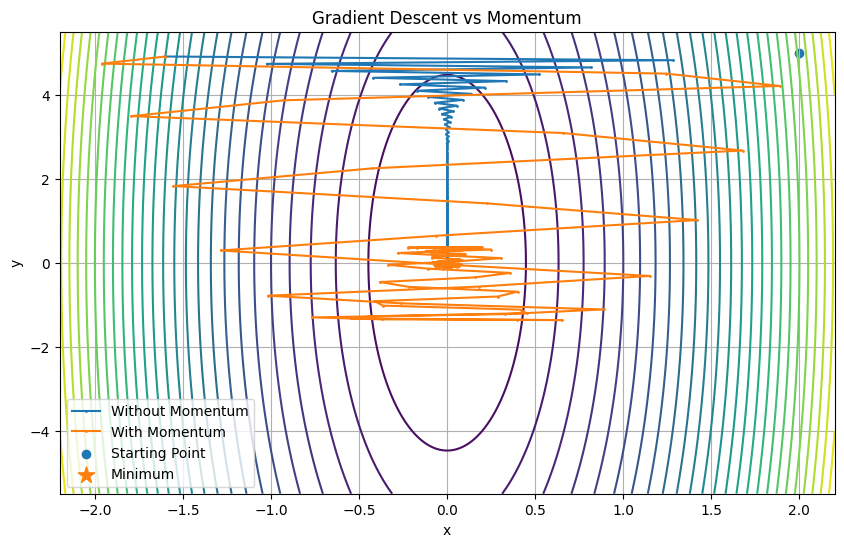

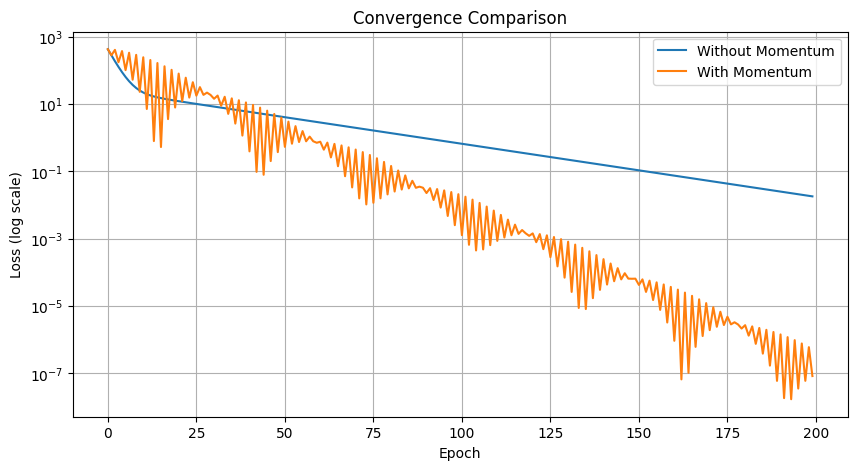

In [29]:
# 7. Plot optimization trajectories
gd_path = torch.tensor(gd_path).numpy()
momentum_path = torch.tensor(momentum_path).numpy()

plt.figure(figsize=(10, 6))

# Loss landscape
x_range = torch.linspace(-2.2, 2.2, 300)
y_range = torch.linspace(-5.5, 5.5, 300)

X, Y = torch.meshgrid(x_range, y_range, indexing="ij")

Z = 100 * X**2 + Y**2

plt.contour(X.numpy(),
            Y.numpy(),
            Z.numpy(),
            levels=30)

# Optimization trajectories
plt.plot(gd_path[:, 0],
         gd_path[:, 1],
         label="Without Momentum",
    marker=".",
    markersize=2)

plt.plot(
    momentum_path[:, 0],
    momentum_path[:, 1],
    label="With Momentum",
    marker=".",
    markersize=2
)

plt.scatter(
    initial_point[0],
    initial_point[1],
    marker="o",
    label="Starting Point"
)

plt.scatter(0, 0, marker="*", s=150, label="Minimum")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Gradient Descent vs Momentum")
plt.legend()
plt.grid()
plt.show()

# 8. Compare loss convergence

plt.figure(figsize=(10, 5))

plt.plot(gd_losses, label="Without Momentum")
plt.plot(momentum_losses, label="With Momentum")

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss (log scale)")
plt.title("Convergence Comparison")

plt.legend()
plt.grid()
plt.show()


### 5.1.5 Adam

**Adam** (Adaptive Moment Estimation) combines momentum with per-parameter adaptive learning rates. It maintains running estimates of the first and second moments of the gradient:

$$
m_{t+1} = \beta_1 m_t + (1 - \beta_1) \nabla_\theta \mathcal{L}(\theta_t)
$$

$$
v_{t+1} = \beta_2 v_t + (1 - \beta_2) (\nabla_\theta \mathcal{L}(\theta_t))^2
$$

Bias correction:

$$
\hat{m}_{t+1} = \frac{m_{t+1}}{1 - \beta_1^{t+1}}, \quad \hat{v}_{t+1} = \frac{v_{t+1}}{1 - \beta_2^{t+1}}
$$

Update:

$$
\theta_{t+1} = \theta_t - \eta \frac{\hat{m}_{t+1}}{\sqrt{\hat{v}_{t+1}} + \epsilon}
$$

The defaults are $ \beta_1 = 0.9 $, $ \beta_2 = 0.999 $, $ \epsilon = 10^{-8} $.

In PyTorch:

### 5.1.6 Summary: Optimizers

| Optimizer | Update Rule | Pros | Cons |
|-----------|-------------|------|------|
| SGD | $ \theta \leftarrow \theta - \eta \nabla \mathcal{L} $ | Simple, interpretable | Slow, sensitive to lr |
| SGD + Momentum | $ v \leftarrow \beta v + \nabla \mathcal{L}; \theta \leftarrow \theta - \eta v $ | Faster, smoother | Extra hyperparameter |
| Adam | Adaptive per-parameter lr | Fast convergence, robust | Can overfit, memory |
| RMSprop | Adaptive lr based on running average | Good for RNNs | Less common |
| Adagrad | Adaptive lr based on accumulated gradients | Good for sparse data | Learning rate decays too fast |

> **Exercise 5.1:** Implement gradient descent for the following functions, and compare the convergence with SGD and Adam.
>
> 1. $ \mathcal{L}(\theta) = \theta^4 - 3\theta^3 + 2 $ (non-convex)
> 2. $ \mathcal{L}(\theta) = \frac{1}{2} \theta^T A \theta $ with $ A = \text{diag}(1, 10, 100) $ (ill-conditioned)
> 3. $ \mathcal{L}(\theta) = \log(1 + e^{-\theta}) $ (logistic loss)

## 5.2 The Canonical Training Loop

### 5.2.1 The Structure of Training

Every training loop in PyTorch follows the same structure:

$$
\text{for epoch} \in \{1, \ldots, E\}:
$$
$$
\quad \text{for batch } (\mathbf{x}, \mathbf{y}) \in \mathcal{D}:
$$
$$
\quad \quad \hat{\mathbf{y}} = f_\theta(\mathbf{x}) \quad \text{(forward pass)}
$$
$$
\quad \quad \mathcal{L} = \ell(\mathbf{y}, \hat{\mathbf{y}}) \quad \text{(loss computation)}
$$
$$
\quad \quad \nabla_\theta \mathcal{L} \quad \text{(backward pass)}
$$
$$
\quad \quad \theta \leftarrow \theta - \eta \nabla_\theta \mathcal{L} \quad \text{(parameter update)}
$$

This is the **canonical training loop**. Every variant — SGD, Adam, distributed training, mixed precision — is a modification of this structure.

### 5.2.2 The `make_train_step` Function

The original notebook introduces a `make_train_step` function that encapsulates the training step:


In [30]:
def make_train_step(model, loss_fn, optimizer):
    def train_step(x, y):
        model.train()
        yhat = model(x)
        loss = loss_fn(y, yhat)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        return loss.item()
    return train_step

This function returns a closure that performs one training step. The training loop becomes:

In [ ]:
train_step = make_train_step(model, loss_fn, optimizer)
losses = []

for epoch in range(n_epochs):
    loss = train_step(x_train_tensor, y_train_tensor)
    losses.append(loss)

### 5.2.3 Why This Pattern Matters

The `make_train_step` pattern separates the **training logic** from the **training loop**. This has several benefits:

**Reusability:** The same training step can be used with different models, losses, and optimizers.

**Readability:** The training loop is reduced to a single function call.

**Testability:** The training step can be tested independently.

**Extensibility:** The training step can be extended with gradient clipping, mixed precision, logging, etc.

### 5.2.4 A More General Training Step

The `make_train_step` function can be extended to include:

- **Gradient clipping:** To prevent exploding gradients.
- **Mixed precision:** To speed up training with float16.
- **Logging:** To record metrics.
- **Gradient accumulation:** To simulate larger batches.


In [31]:
def make_train_step(model, loss_fn, optimizer, clip_grad=None, use_amp=False, log_fn=None):
    scaler = torch.cuda.amp.GradScaler() if use_amp else None

    def train_step(x, y):
        model.train()

        with torch.cuda.amp.autocast() if use_amp else torch.no_grad():
            yhat = model(x)
            loss = loss_fn(y, yhat)

        if use_amp:
            scaler.scale(loss).backward()
            if clip_grad is not None:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            if clip_grad is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)
            optimizer.step()

        optimizer.zero_grad()

        if log_fn is not None:
            log_fn(loss.item())

        return loss.item()

    return train_step

### 5.2.5 Summary: The Training Loop

| Component | Mathematical Form | PyTorch |
|-----------|-------------------|---------|
| Forward pass | $ \hat{\mathbf{y}} = f_\theta(\mathbf{x}) $ | `yhat = model(x)` |
| Loss computation | $ \mathcal{L} = \ell(\mathbf{y}, \hat{\mathbf{y}}) $ | `loss = loss_fn(y, yhat)` |
| Backward pass | $ \nabla_\theta \mathcal{L} $ | `loss.backward()` |
| Parameter update | $ \theta \leftarrow \theta - \eta \nabla \mathcal{L} $ | `optimizer.step()` |
| Gradient zeroing | $ \nabla \mathcal{L} \leftarrow 0 $ | `optimizer.zero_grad()` |
| Training mode | — | `model.train()` |

> **Exercise 5.2:** Implement the `make_train_step` function with the following extensions:
>
> 1. Gradient clipping with a configurable maximum norm.
> 2. Mixed precision training using `torch.cuda.amp`.
> 3. Logging of the loss to a list.
> 4. Early stopping based on validation loss.

## 5.3 Loss Functions

### 5.3.1 The Role of the Loss Function

The loss function $ \ell(\mathbf{y}, \hat{\mathbf{y}}) $ quantifies the discrepancy between the true target $ \mathbf{y} $ and the model's prediction $ \hat{\mathbf{y}} $. It defines the optimization objective:

$$
\mathcal{L}(\theta) = \frac{1}{N} \sum_{i=1}^N \ell(\mathbf{y}_i, f_\theta(\mathbf{x}_i))
$$

The choice of loss function encodes assumptions about the data distribution and the task.

### 5.3.2 Mean Squared Error (MSE)

$$
\ell_{\text{MSE}}(\mathbf{y}, \hat{\mathbf{y}}) = \frac{1}{d} \sum_{j=1}^d (y_j - \hat{y}_j)^2
$$

MSE assumes Gaussian noise and penalizes large errors quadratically. It is differentiable everywhere and is the default for regression.

In [32]:
loss_fn = nn.MSELoss(reduction='mean')

### 5.3.3 Mean Absolute Error (MAE)

$$
\ell_{\text{MAE}}(\mathbf{y}, \hat{\mathbf{y}}) = \frac{1}{d} \sum_{j=1}^d |y_j - \hat{y}_j|
$$

MAE assumes Laplace noise and is robust to outliers. It is not differentiable at 0, requiring subgradient methods.

In PyTorch:

In [ ]:
loss_fn = nn.L1Loss(reduction='mean')

## 5.3.4 Cross-Entropy Loss

For classification with $ C $ classes, the cross-entropy loss is:

$$
\ell_{\text{CE}}(\mathbf{y}, \hat{\mathbf{y}}) = -\sum_{c=1}^C y_c \log \hat{y}_c
$$

where $ \mathbf{y} $ is a one-hot target and $ \hat{\mathbf{y}} = \text{softmax}(\mathbf{z}) $ is the predicted probability.

In PyTorch:

In [33]:
loss_fn = nn.CrossEntropyLoss()

**Note:** `nn.CrossEntropyLoss` combines `log_softmax` and `nll_loss`, so you should pass the raw logits (not softmax outputs) as predictions.

### 5.3.5 Binary Cross-Entropy Loss

For binary classification:

$$
\ell_{\text{BCE}}(y, \hat{y}) = -[y \log \hat{y} + (1 - y) \log(1 - \hat{y})]
$$

In PyTorch:

In [34]:
loss_fn = nn.BCELoss()  # Expects probabilities
loss_fn = nn.BCEWithLogitsLoss()  # Expects logits

### 5.3.6 Custom Loss Functions

You can define custom loss functions as subclasses of `nn.Module`:


In [35]:
class HuberLoss(nn.Module):
    def __init__(self, delta=1.0):
        super().__init__()
        self.delta = delta

    def forward(self, y_true, y_pred):
        error = y_true - y_pred
        abs_error = error.abs()
        quadratic = 0.5 * error ** 2
        linear = self.delta * (abs_error - 0.5 * self.delta)
        return torch.where(abs_error < self.delta, quadratic, linear).mean()

### 5.3.7 Summary: Loss Functions

| Loss | Formula | Task | PyTorch |
|------|---------|------|---------|
| MSE | $ \frac{1}{d} \sum (y - \hat{y})^2 $ | Regression | `nn.MSELoss()` |
| MAE | $ \frac{1}{d} \sum \|y - \hat{y}\| $ | Regression (robust) | `nn.L1Loss()` |
| Huber | Quadratic near 0, linear away | Regression (robust) | Custom |
| Cross-entropy | $ -\sum y \log \hat{y} $ | Multi-class | `nn.CrossEntropyLoss()` |
| BCE | $ -[y \log \hat{y} + (1-y)\log(1-\hat{y})] $ | Binary | `nn.BCEWithLogitsLoss()` |
| NLL | $ -\sum \log p(y) $ | Probabilistic | `nn.NLLLoss()` |

> **Exercise 5.3:** Implement the following loss functions from scratch, then compare with PyTorch's built-in versions.
>
> 1. MSE
> 2. MAE
> 3. Huber loss
> 4. Binary cross-entropy
> 5. Cross-entropy for multi-class classification


## 5.4 Optimizers

### 5.4.1 The `torch.optim` Module

PyTorch provides a variety of optimizers in `torch.optim`. All share the same API:

```python
optimizer = optim.SGD(model.parameters(), lr=0.1)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
optimizer = optim.RMSprop(model.parameters(), lr=1e-3)
optimizer = optim.Adagrad(model.parameters(), lr=1e-2)
```

| Method | Description |
|--------|-------------|
| `optimizer.step()` | Update parameters |
| `optimizer.zero_grad()` | Zero gradients |
| `optimizer.state_dict()` | Get optimizer state |
| `optimizer.load_state_dict()` | Load optimizer state |
| `optimizer.param_groups` | Access parameter groups |

### 5.4.2 Learning Rate

The **learning rate** $ \eta $ is the most important hyperparameter. Too small, and training is slow. Too large, and training diverges.

**Worked example 5.4:** Consider the quadratic $ \mathcal{L}(\theta) = \theta^2 $. Gradient descent with learning rate $ \eta $ converges if $ 0 < \eta < 1 $. At $ \eta = 0.1 $, convergence is fast. At $ \eta = 0.9 $, convergence is oscillatory. At $ \eta = 1.1 $, it diverges.

In [36]:
def train_with_lr(lr, n_steps=20):
    theta = torch.tensor(5.0)
    for _ in range(n_steps):
        grad = 2 * theta
        theta = theta - lr * grad
    return theta.item()

for lr in [0.01, 0.1, 0.5, 0.9, 1.1]:
    final = train_with_lr(lr)
    print(f"lr={lr}: final theta={final:.6f}")

lr=0.01: final theta=3.338040
lr=0.1: final theta=0.057646
lr=0.5: final theta=0.000000
lr=0.9: final theta=0.057646
lr=1.1: final theta=191.688248


### 5.4.3 Momentum

Momentum accumulates a velocity vector to smooth updates:

$$
v_{t+1} = \beta v_t + \nabla_\theta \mathcal{L}(\theta_t)
$$
$$
\theta_{t+1} = \theta_t - \eta v_{t+1}
$$

In PyTorch:

In [37]:
optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9)

### 5.4.4 Adam

Adam combines momentum with adaptive learning rates:

$$
m_{t+1} = \beta_1 m_t + (1 - \beta_1) \nabla \mathcal{L}
$$
$$
v_{t+1} = \beta_2 v_t + (1 - \beta_2) (\nabla \mathcal{L})^2
$$
$$
\theta_{t+1} = \theta_t - \eta \frac{\hat{m}_{t+1}}{\sqrt{\hat{v}_{t+1}} + \epsilon}
$$

In PyTorch:

In [38]:
optimizer = optim.Adam(model.parameters(), lr=1e-3, betas=(0.9, 0.999), eps=1e-8)

### 5.4.5 Parameter Groups

You can apply different hyperparameters to different parts of the model using parameter groups:


In [40]:
class LinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(1, 1)

    def forward(self, x):
        return self.linear(x)

In [41]:
optimizer = optim.SGD(
    model.parameters(),
    lr=1e-3,
    momentum=0.9
)

In [42]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Linear(10, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU())

        self.classifier = nn.Linear(32, 2)

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = NeuralNetwork()

optimizer = optim.SGD([{'params': model.features.parameters(),
                        'lr': 1e-4},
                         {'params': model.classifier.parameters(),
                          'lr': 1e-3}],
                      momentum=0.9)

This is common in transfer learning, where you want a smaller learning rate for pre-trained layers and a larger one for the new classifier.

### 5.4.6 Summary: Optimizers

| Optimizer | Key Hyperparameters | When to Use |
|-----------|---------------------|-------------|
| SGD | `lr`, `momentum`, `weight_decay` | Vision, when you can tune lr |
| Adam | `lr`, `betas`, `eps`, `weight_decay` | NLP, transformers, default |
| AdamW | `lr`, `betas`, `eps`, `weight_decay` | Transformers (decoupled weight decay) |
| RMSprop | `lr`, `alpha`, `eps` | RNNs, reinforcement learning |
| Adagrad | `lr`, `lr_decay`, `eps` | Sparse data |

> **Exercise 5.4:** Compare the convergence of SGD, SGD with momentum, Adam, and AdamW on the linear regression problem. Plot the loss curves. Which converges fastest? Which is most stable? Which gives the best final loss?

## 5.5 Learning Rate Schedules

### 5.5.1 Why Schedule the Learning Rate?

A fixed learning rate is rarely optimal. Early in training, a large learning rate helps escape poor local minima. Later, a small learning rate helps fine-tune the parameters. **Learning rate schedules** adjust the learning rate over time.

### 5.5.2 Common Schedules

**Step decay:** Reduce the learning rate by a factor every $ k $ epochs:

$$
\eta_t = \eta_0 \cdot \gamma^{\lfloor t / k \rfloor}
$$

**Exponential decay:**

$$
\eta_t = \eta_0 \cdot \gamma^t
$$

**Cosine annealing:**

$$
\eta_t = \eta_{\min} + \frac{1}{2}(\eta_{\max} - \eta_{\min})\left(1 + \cos\left(\frac{t}{T}\pi\right)\right)
$$

**Linear warmup + decay:** Increase the learning rate linearly for the first $ T_w $ steps, then decay:

$$
\eta_t = \begin{cases} \eta_{\max} \cdot \frac{t}{T_w} & t < T_w \\ \eta_{\max} \cdot \text{decay}(t) & t \geq T_w \end{cases}
$$

### 5.5.3 Implementing Schedules in PyTorch

In [44]:
# Step decay
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=30, gamma=0.1)

# Exponential decay
scheduler = optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.95)

# Cosine annealing
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=100)

# Reduce on plateau
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=10)

### 5.5.4 Using Schedulers in the Training Loop

```python
for epoch in range(n_epochs):
    train_step(...)
    val_loss = evaluate(...)
    scheduler.step(val_loss)  # For ReduceLROnPlateau
    # scheduler.step()  # For other schedulers
```

### 5.5.5 Summary: Learning Rate Schedules

| Schedule | Formula | Use Case |
|----------|---------|----------|
| Step decay | $ \eta_0 \gamma^{\lfloor t/k \rfloor} $ | Classic, simple |
| Exponential decay | $ \eta_0 \gamma^t $ | Smooth decay |
| Cosine annealing | $ \eta_{\min} + \frac{1}{2}(\eta_{\max} - \eta_{\min})(1 + \cos(\pi t/T)) $ | Modern, transformers |
| Linear warmup | $ \eta_{\max} t / T_w $ | Transformers, large batches |
| Reduce on plateau | $ \eta \leftarrow \eta \gamma $ when metric plateaus | Adaptive, robust |

> **Exercise 5.5:** Implement the following learning rate schedules and plot the learning rate over 100 epochs:
>
> 1. Step decay with step size 30 and gamma 0.1
> 2. Exponential decay with gamma 0.95
> 3. Cosine annealing with T_max = 100
> 4. Linear warmup (10 epochs) + cosine decay


## 5.6 Evaluation Loops

### 5.6.1 The Structure of Evaluation

The evaluation loop is structurally similar to the training loop, with three key differences:

1. **No gradient computation:** Use `torch.no_grad()`.
2. **No parameter updates:** Do not call `optimizer.step()`.
3. **Evaluation mode:** Call `model.eval()` to disable dropout and use running statistics in batch norm.

The evaluation loop computes the loss (and other metrics) on the validation set:

$$
\mathcal{L}_{\text{val}} = \frac{1}{N_{\text{val}}} \sum_{i=1}^{N_{\text{val}}} \ell(\mathbf{y}_i^{\text{val}}, f_\theta(\mathbf{x}_i^{\text{val}}))
$$

### 5.6.2 The Evaluation Loop


In [45]:
def evaluate(model, loss_fn, val_loader, device):
    model.eval()
    val_losses = []
    with torch.no_grad():
        for x_val, y_val in val_loader:
            x_val = x_val.to(device)
            y_val = y_val.to(device)
            yhat = model(x_val)
            val_loss = loss_fn(y_val, yhat)
            val_losses.append(val_loss.item())
    return sum(val_losses) / len(val_losses)

### 5.6.3 Metrics Beyond Loss

For classification tasks, accuracy is often more informative than loss:

$$
\text{Accuracy} = \frac{1}{N} \sum_{i=1}^N \mathbb{1}[\arg\max \hat{\mathbf{y}}_i = y_i]
$$

For imbalanced datasets, precision, recall, and F1 are more informative:

$$
\text{Precision} = \frac{TP}{TP + FP}, \quad \text{Recall} = \frac{TP}{TP + FN}, \quad F_1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}
$$

In PyTorch:


In [46]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def compute_metrics(y_true, y_pred):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, average='macro'),
        'recall': recall_score(y_true, y_pred, average='macro'),
        'f1': f1_score(y_true, y_pred, average='macro')
    }

## 5.6.4 Early Stopping

**Early stopping** halts training when the validation loss stops improving:

In [ ]:
best_val_loss = float('inf')
patience = 10
patience_counter = 0

for epoch in range(n_epochs):
    train_loss = train_step(...)
    val_loss = evaluate(...)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(model.state_dict(), 'best_model.pth')
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

### 5.6.5 Summary: Evaluation

| Component | Description | PyTorch |
|-----------|-------------|---------|
| Evaluation mode | Disable dropout, use running stats | `model.eval()` |
| No gradients | Disable gradient tracking | `torch.no_grad()` |
| No updates | Do not call optimizer | — |
| Metrics | Accuracy, precision, recall, F1 | `sklearn.metrics` |
| Early stopping | Halt when val loss plateaus | Custom logic |
| Checkpointing | Save best model | `torch.save` |

> **Exercise 5.6:** Implement a complete training and evaluation pipeline with:
>
> 1. Training loop with mini-batches.
> 2. Validation loop with `torch.no_grad()`.
> 3. Early stopping based on validation loss.
> 4. Checkpointing of the best model.
> 5. Logging of training and validation losses to a CSV file.
> 6. Plotting of the loss curves.

---

## 5.7 Checkpointing and Resuming Training

### 5.7.1 Why Checkpoint?

Training deep models can take hours, days, or weeks. Checkpointing allows you to:
- Resume training after an interruption.
- Save the best model for evaluation.
- Share models with collaborators.
- Reproduce results.

### 5.7.2 What to Save

A complete checkpoint includes:
- The model's `state_dict()`.
- The optimizer's `state_dict()`.
- The current epoch.
- The best validation loss.
- The learning rate scheduler's state.

```python
checkpoint = {
    'epoch': epoch,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'scheduler_state_dict': scheduler.state_dict(),
    'best_val_loss': best_val_loss,
    'train_losses': train_losses,
    'val_losses': val_losses
}
torch.save(checkpoint, 'checkpoint.pth')
```

### 5.7.3 Resuming Training

```python
checkpoint = torch.load('checkpoint.pth')
model.load_state_dict(checkpoint['model_state_dict'])
optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
start_epoch = checkpoint['epoch'] + 1
best_val_loss = checkpoint['best_val_loss']

for epoch in range(start_epoch, n_epochs):
    ...
```

### 5.7.4 Summary: Checkpointing

| Component | Save | Load |
|-----------|------|------|
| Model | `model.state_dict()` | `model.load_state_dict()` |
| Optimizer | `optimizer.state_dict()` | `optimizer.load_state_dict()` |
| Scheduler | `scheduler.state_dict()` | `scheduler.load_state_dict()` |
| Epoch | `epoch` | `start_epoch` |
| Best loss | `best_val_loss` | `best_val_loss` |

> **Exercise 5.7:** Implement a checkpointing system that saves a checkpoint every 10 epochs and allows resuming training. Test it by interrupting training and resuming from the last checkpoint.

---

## 5.8 Worked Example: Full Training Pipeline

Let us combine everything we have learned into a complete training pipeline.

### 5.8.1 Data Generation

In [48]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from torch.utils.data import DataLoader, TensorDataset

def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)

set_seed(42)

# Generate data
N = 1000
x = torch.rand(N, 1)
y = 1 + 2 * x + 0.1 * torch.randn(N, 1)

# Train/validation split
idx = torch.randperm(N)
train_idx = idx[:800]
val_idx = idx[800:]
x_train, y_train = x[train_idx], y[train_idx]
x_val, y_val = x[val_idx], y[val_idx]

# DataLoader
train_dataset = TensorDataset(x_train, y_train)
val_dataset = TensorDataset(x_val, y_val)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

# Device
device = "cuda" if torch.cuda.is_available() else "cpu"

### 5.8.2 Model Definition

In [49]:
class LinearRegression(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(1, 1)

    def forward(self, x):
        return self.linear(x)

model = LinearRegression().to(device)

### 5.8.3 Loss, Optimizer, and Scheduler

In [50]:
loss_fn = nn.MSELoss(reduction='mean')
optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.5)

### 5.8.4 Training Step

In [51]:
def make_train_step(model, loss_fn, optimizer):
    def train_step(x, y):
        model.train()
        yhat = model(x)
        loss = loss_fn(y, yhat)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        return loss.item()
    return train_step

train_step = make_train_step(model, loss_fn, optimizer)

### 5.8.5 Training Loop with Early Stopping


In [52]:
n_epochs = 200
best_val_loss = float('inf')
patience = 20
patience_counter = 0
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    # Training
    epoch_train_losses = []
    for x_batch, y_batch in train_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)
        loss = train_step(x_batch, y_batch)
        epoch_train_losses.append(loss)
    train_loss = np.mean(epoch_train_losses)
    train_losses.append(train_loss)

    # Validation
    model.eval()
    epoch_val_losses = []
    with torch.no_grad():
        for x_val_batch, y_val_batch in val_loader:
            x_val_batch = x_val_batch.to(device)
            y_val_batch = y_val_batch.to(device)
            yhat = model(x_val_batch)
            val_loss = loss_fn(y_val_batch, yhat)
            epoch_val_losses.append(val_loss.item())
    val_loss = np.mean(epoch_val_losses)
    val_losses.append(val_loss)

    # Scheduler
    scheduler.step()

    # Early stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(model.state_dict(), 'best_model.pth')
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

    if epoch % 10 == 0:
        print(f"Epoch {epoch}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}")

Epoch 0: train_loss=1.1667, val_loss=0.3480
Epoch 10: train_loss=0.0113, val_loss=0.0119
Epoch 20: train_loss=0.0107, val_loss=0.0117
Early stopping at epoch 22


### 5.8.6 Reflection

This pipeline illustrates the full training workflow. The data is split into training and validation sets and wrapped in `DataLoader`s. The model is defined as a subclass of `nn.Module`. The loss, optimizer, and scheduler are created. The training step encapsulates the forward pass, loss computation, backward pass, and parameter update. The training loop iterates over epochs and batches, computes training and validation losses, steps the scheduler, and applies early stopping. The best model is saved to disk.

**Research relevance:** This is the canonical training pipeline in PyTorch. Every research project you run will follow this structure, with modifications for the specific model, data, and task.

> **Exercise 5.8:** Extend the pipeline above to include:
>
> 1. A two-layer MLP with ReLU activation.
> 2. Adam optimizer with learning rate 1e-3.
> 3. Cosine annealing learning rate schedule.
> 4. Gradient clipping with max norm 1.0.
> 5. TensorBoard logging of the loss curves.
> 6. Checkpointing every 10 epochs.
> 7. Resuming from a checkpoint.

---

## 5.9 Common Errors and Debugging

### 5.9.1 Error: Loss Not Decreasing

**Symptoms:** The loss stays constant or oscillates.

**Causes:**
- Learning rate too high or too low.
- Wrong loss function for the task.
- Bug in the forward pass.
- Vanishing or exploding gradients.

**Fixes:**
- Try different learning rates (e.g., 1e-5, 1e-4, 1e-3, 1e-2, 1e-1).
- Check the loss function (e.g., cross-entropy expects logits, not probabilities).
- Print intermediate values in the forward pass.
- Use gradient clipping or gradient normalization.

### 5.9.2 Error: Loss Exploding

**Symptoms:** The loss becomes NaN or infinity.

**Causes:**
- Learning rate too high.
- Numerical instability (e.g., log of zero, division by zero).
- Exploding gradients.

**Fixes:**
- Reduce the learning rate.
- Add epsilon to denominators.
- Use gradient clipping.
- Use mixed precision with loss scaling.

### 5.9.3 Error: Overfitting

**Symptoms:** Training loss decreases but validation loss increases.

**Causes:**
- Model too large for the data.
- Too many epochs.
- No regularization.

**Fixes:**
- Add dropout.
- Add weight decay.
- Use early stopping.
- Reduce model size.
- Increase data.

### 5.9.4 Error: Underfitting

**Symptoms:** Both training and validation losses are high.

**Causes:**
- Model too small.
- Learning rate too low.
- Not enough epochs.
- Wrong architecture.

**Fixes:**
- Increase model size.
- Increase learning rate.
- Train longer.
- Try a different architecture.

### 5.9.5 Summary: Common Training Issues

| Issue | Symptom | Cause | Fix |
|-------|---------|-------|-----|
| Loss not decreasing | Flat loss curve | LR wrong, bug in forward | Tune LR, check forward |
| Loss exploding | NaN or inf | LR too high, numerical instability | Reduce LR, add epsilon |
| Overfitting | Train down, val up | Model too large, no regularization | Dropout, weight decay, early stopping |
| Underfitting | Both losses high | Model too small, LR too low | Increase model, LR, epochs |
| Slow convergence | Gradual loss decrease | LR too low, poor initialization | Increase LR, better init |
| Oscillating loss | Loss jumps | LR too high, batch too small | Reduce LR, increase batch |

> **Exercise 5.9:** For each of the following scenarios, diagnose the issue and propose a fix:
>
> 1. Training loss decreases but validation loss increases after 50 epochs.
> 2. Loss is NaN after 10 epochs.
> 3. Loss oscillates between 0.5 and 2.0.
> 4. Loss decreases very slowly.
> 5. Both training and validation losses are high and flat.


## 5.10 Research Application: Hyperparameter Tuning

### 5.10.1 Why Hyperparameter Tuning Matters

Hyperparameters (learning rate, batch size, weight decay, etc.) significantly affect model performance. Tuning them is a standard part of research.

### 5.10.2 Grid Search

**Grid search** evaluates all combinations of a predefined set of hyperparameters:

```python
from itertools import product

learning_rates = [1e-4, 1e-3, 1e-2]
batch_sizes = [16, 32, 64]
weight_decays = [0, 1e-4, 1e-3]

for lr, bs, wd in product(learning_rates, batch_sizes, weight_decays):
    model = LinearRegression().to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    train_loader = DataLoader(train_dataset, batch_size=bs, shuffle=True)
    # Train and evaluate
    ...
```

### 5.10.3 Random Search

**Random search** samples hyperparameters from distributions:

In [54]:
import random
n_trials = 10
for _ in range(n_trials):
    lr = 10 ** random.uniform(-5, -2)
    bs = random.choice([16, 32, 64, 128])
    wd = 10 ** random.uniform(-6, -2)
    # Train and evaluate

### 5.10.4 Bayesian Optimization

**Bayesian optimization** uses a probabilistic model to guide the search. Libraries like `optuna` and `ray.tune` implement this.

In [56]:
# Uncomment this
#!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [57]:
import optuna

def objective(trial):
    lr = trial.suggest_float('lr', 1e-5, 1e-2, log=True)
    bs = trial.suggest_categorical('batch_size', [16, 32, 64])
    wd = trial.suggest_float('weight_decay', 1e-6, 1e-2, log=True)
    # Train and evaluate
    return val_loss

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=50)

[I 2026-11-26 13:23:16,018] A new study created in memory with name: no-name-293ba770-146e-4569-81a3-f076f50be8fc
[I 2026-11-26 13:23:16,023] Trial 0 finished with value: 0.012233864915158068 and parameters: {'lr': 1.939168112730686e-05, 'batch_size': 64, 'weight_decay': 3.786241304846388e-05}. Best is trial 0 with value: 0.012233864915158068.
[I 2026-11-26 13:23:16,025] Trial 1 finished with value: 0.012233864915158068 and parameters: {'lr': 0.0061251486057632126, 'batch_size': 64, 'weight_decay': 1.4456098000672571e-06}. Best is trial 0 with value: 0.012233864915158068.
[I 2026-11-26 13:23:16,028] Trial 2 finished with value: 0.012233864915158068 and parameters: {'lr': 3.21270448552065e-05, 'batch_size': 32, 'weight_decay': 0.000728011311094388}. Best is trial 0 with value: 0.012233864915158068.
[I 2026-11-26 13:23:16,030] Trial 3 finished with value: 0.012233864915158068 and parameters: {'lr': 0.0002777943672716665, 'batch_size': 32, 'weight_decay': 0.005945718358938293}. Best is tr

### 5.10.5 Research Relevance

Hyperparameter tuning is a standard part of research. When reporting results, always specify:
- The search space.
- The search method.
- The number of trials.
- The best hyperparameters.
- The random seed(s).

### 5.10.6 Summary: Hyperparameter Tuning

| Method | Pros | Cons |
|--------|------|------|
| Grid search | Simple, exhaustive | Exponential in #params |
| Random search | Scales better | May miss optimal |
| Bayesian optimization | Efficient | Complex, requires library |
| Population-based | Parallel, adaptive | Complex |

> **Exercise 5.10:** Perform a hyperparameter search for the linear regression model over:
>
> 1. Learning rate: [1e-4, 1e-3, 1e-2, 1e-1]
> 2. Batch size: [16, 32, 64]
> 3. Optimizer: [SGD, Adam]
>
> Report the best combination and the corresponding validation loss.

---

## 5.11 Module Summary

| Concept | Mathematical Form | PyTorch | Research Relevance |
|---------|-------------------|---------|-------------------|
| Optimization | $ \theta^* = \arg\min_\theta \mathcal{L}(\theta) $ | — | Core of training |
| Gradient descent | $ \theta \leftarrow \theta - \eta \nabla \mathcal{L} $ | `optimizer.step()` | Basic optimizer |
| SGD | $ \theta \leftarrow \theta - \eta \nabla \mathcal{L}_\mathcal{B} $ | `optim.SGD` | Standard optimizer |
| Momentum | $ v \leftarrow \beta v + \nabla \mathcal{L} $ | `momentum=0.9` | Accelerated SGD |
| Adam | Adaptive per-parameter lr | `optim.Adam` | Default for many tasks |
| Loss function | $ \ell(\mathbf{y}, \hat{\mathbf{y}}) $ | `nn.MSELoss`, `nn.CrossEntropyLoss` | Objective |
| Training loop | Forward, backward, update | — | Core structure |
| Training step | Encapsulated | `make_train_step` | Reusability |
| Evaluation loop | No gradients, no updates | `model.eval()`, `torch.no_grad()` | Validation |
| Learning rate schedule | $ \eta_t = f(t) $ | `optim.lr_scheduler` | Convergence |
| Early stopping | Halt when val plateaus | Custom logic | Regularization |
| Checkpointing | Save/load state | `torch.save`, `torch.load` | Reproducibility |
| Hyperparameter tuning | Search over hyperparameters | `optuna`, `ray.tune` | Performance |

---

## 5.12 Capstone Thread: Training Skills for Your Project

By the end of this module, you should be able to write a complete training loop from scratch; choose appropriate optimizers and loss functions for a given task; implement learning rate schedules; write evaluation loops; checkpoint and resume training; and articulate why training loops are the heart of every deep learning experiment.

For your capstone project, you will need these skills to train your model, monitor its progress, tune its hyperparameters, and report its results.

In Module 6, we will build on this foundation to study **data pipelines** — how to load, preprocess, and feed data to your model.

---

## 5.13 Additional Resources

### On Optimization

- Ruder, S. (2016). "An Overview of Gradient Descent Optimization Algorithms." *arXiv:1609.04747*.
- Kingma, D. P., & Ba, J. (2014). "Adam: A Method for Stochastic Optimization." *ICLR*.
- Loshchilov, I., & Hutter, F. (2017). "Decoupled Weight Decay Regularization." *ICLR*.
- Smith, L. N. (2017). "Cyclical Learning Rates for Training Neural Networks." *WACV*.

### On Training Deep Networks

- Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep Learning*. MIT Press. Chapter 8: Optimization for Training Deep Models.
- Bengio, Y. (2012). "Practical Recommendations for Gradient-Based Training of Deep Architectures." *arXiv:1206.5533*.

### On Hyperparameter Tuning

- Bergstra, J., & Bengio, Y. (2012). "Random Search for Hyper-Parameter Optimization." *JMLR*.
- Snoek, J., Larochelle, H., & Adams, R. P. (2012). "Practical Bayesian Optimization of Machine Learning Algorithms." *NeurIPS*.
- Optuna: [Link](https://optuna.org/)

### On PyTorch Training

- PyTorch training documentation: [Link](https://pytorch.org/tutorials/beginner/basics/optimization_tutorial.html)
- PyTorch learning rate scheduler documentation: [Link](https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate)

---
*End of Module 5*